<a href="https://colab.research.google.com/github/gag-ana/natural-language-to-shellcommand-helper/blob/main/llm_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tiktoken sacrebleu gradio

Mounted at /content/drive
Device: cuda | seed: 123
Raw pairs: 12607
After cleaning: 12596
Train 10710 | Val 638 | Test 1248  (no task shared between splits)
train: n= 10710  mean tokens=  83.1  max tokens=225
val  : n=   638  mean tokens=  83.1  max tokens=169
test : n=  1248  mean tokens=  82.7  max tokens=173
Evaluation subset: 300 test examples
Batches per epoch -> train: 1338 | val: 80
Collate check OK (padding targets are -100)


checkpoint: 100%|██████████| 77.0/77.0 [00:00<00:00, 198kiB/s]
encoder.json: 100%|██████████| 1.04M/1.04M [00:00<00:00, 2.68MiB/s]
hparams.json: 100%|██████████| 90.0/90.0 [00:00<00:00, 129kiB/s]
model.ckpt.data-00000-of-00001: 100%|██████████| 498M/498M [01:16<00:00, 6.49MiB/s]
model.ckpt.index: 100%|██████████| 5.21k/5.21k [00:00<00:00, 12.2MiB/s]
model.ckpt.meta: 100%|██████████| 471k/471k [00:00<00:00, 1.80MiB/s]
vocab.bpe: 100%|██████████| 456k/456k [00:00<00:00, 1.75MiB/s]


GPT-2 124M loaded: 163.0M parameters

Before training -> train loss 4.1589 | val loss 4.1759
TASK : Create a copy of the current working directory structure in the usr/project directory,
REF  : find . -type d -print|sed 's@^@/usr/project/@'|xargs mkdir -p
BASE : 'Write a response that is suitable for the task.\n\n### Output:\n\nWrite a response that is suitable for the task.\n\n### Error'

TASK : Move all files/directories under current directory to ~/play
REF  : find . -exec mv '{}' ~/play/ \;
BASE : 'Write a response that is valid for the current directory.\n\n### Output:\n\nWrite a response that is valid for the current d'

TASK : ERROR - need to add -a or -r for recursive copy
REF  : rsync --exclude='B/' --exclude='C/' . anotherhost:/path/to/target/directory
BASE : 'ERROR - need to add -a or -r for recursive copy\n\n### Response:\n\nERROR - need to add -a or -r for recursive copy\n\n### Res'

TASK : Search all *.c files from the current directory tree for "hogehoge"
REF  : find . -

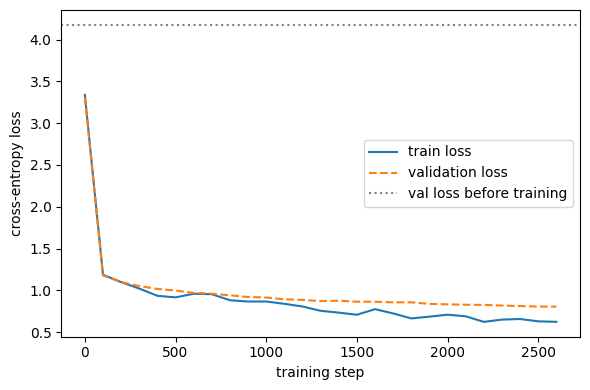


Save/reload check -> identical weights: True | same predicted tokens: True | max logit difference: 0.00147

Generating commands for the held-out evaluation set...
50/300 done  [22s]
100/300 done  [44s]
150/300 done  [61s]
200/300 done  [80s]
250/300 done  [103s]
300/300 done  [124s]

base_model_10_prompts        n= 10 | exact   0.0% | exact(any ref)   0.0% | first-word  20.0% | BLEU   0.3 | chrF   6.7
finetuned_same_10_prompts    n= 10 | exact   0.0% | exact(any ref)   0.0% | first-word  70.0% | BLEU  28.1 | chrF  43.8
finetuned_all_300            n=300 | exact   7.0% | exact(any ref)   7.7% | first-word  75.3% | BLEU  25.5 | chrF  48.3

================ MANUAL CHECK (30 outputs) ================

[ 1] TASK: Read a single character from standard input into variable "key" without backslash escapes and using the prompt "Press any key to continue..."
     REF : read -n1 -r -p "Press any key to continue..." key
     OURS: read -p "Press any key to continue..."

[ 2] TASK: Number each non-

In [8]:

!pip install -q tiktoken sacrebleu gradio

import os, re, json, random, time, urllib.request
from collections import Counter
from functools import partial

import numpy as np
import torch
import torch.nn as nn
import tiktoken
from torch.utils.data import Dataset, DataLoader

# ---------- Google Drive (everything is saved here) ----------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = "/content/drive/MyDrive/nl2bash_project"
except ImportError:
    DRIVE = "nl2bash_project"
os.makedirs(DRIVE, exist_ok=True)
RESULTS_DIR = f"{DRIVE}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
CKPT = f"{DRIVE}/gpt2-124M-nl2bash.pth"          # do NOT submit this file (rules: no weight files)

# ---------- settings ----------
SEED = 123
DATA_DIR = "data"
NL_URL = "https://raw.githubusercontent.com/TellinaTool/nl2bash/master/data/bash/all.nl"
CM_URL = "https://raw.githubusercontent.com/TellinaTool/nl2bash/master/data/bash/all.cm"
TRAIN_FRAC, VAL_FRAC = 0.85, 0.05                 # test = remaining 10 %
MAX_CHARS = 300
INSTRUCTION = "Convert the task to a Linux shell command."

MODEL_SIZE = "124M"
BASE_CONFIG = {"vocab_size": 50257, "context_length": 1024, "drop_rate": 0.0, "qkv_bias": True}
MODEL_CONFIGS = {
    "124M": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "355M": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
}
ALLOWED_MAX_LENGTH = 256
BATCH_SIZE = 8
LR = 5e-5
WEIGHT_DECAY = 0.1
NUM_EPOCHS = 2
PAD_TOKEN_ID = 50256
IGNORE_INDEX = -100
EVAL_N = 300
MAX_NEW_TOKENS = 100


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| seed:", SEED)
if device.type == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU, then run again.")
tokenizer = tiktoken.get_encoding("gpt2")
CFG = {**BASE_CONFIG, **MODEL_CONFIGS[MODEL_SIZE]}

# ====================== DATA ======================
ALPACA_HEADER = ("Below is an instruction that describes a task. "
                 "Write a response that appropriately completes the request.")


def build_prompt(entry):
    """Prompt only (used in training AND at inference)."""
    text = f"{ALPACA_HEADER}\n\n### Instruction:\n{entry['instruction']}"
    if entry.get("input"):
        text += f"\n\n### Input:\n{entry['input']}"
    return text + "\n\n### Response:\n"


def format_full(entry):
    return build_prompt(entry) + entry["output"]


def download(url, path):
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)


os.makedirs(DATA_DIR, exist_ok=True)
download(NL_URL, f"{DATA_DIR}/all.nl")
download(CM_URL, f"{DATA_DIR}/all.cm")
with open(f"{DATA_DIR}/all.nl", encoding="utf-8") as f:
    nl = [l.strip() for l in f]
with open(f"{DATA_DIR}/all.cm", encoding="utf-8") as f:
    cm = [l.strip() for l in f]
assert len(nl) == len(cm)
print("Raw pairs:", len(nl))

seen, pairs = set(), []
for task, cmd in zip(nl, cm):
    task, cmd = " ".join(task.split()), cmd.strip()
    if not task or not cmd or len(task) > MAX_CHARS or len(cmd) > MAX_CHARS:
        continue
    if (task, cmd) in seen:
        continue
    seen.add((task, cmd))
    pairs.append({"instruction": INSTRUCTION, "input": task, "output": cmd})
print("After cleaning:", len(pairs))

# split by UNIQUE English task, so no task appears in two splits
tasks = sorted({e["input"] for e in pairs})
random.Random(SEED).shuffle(tasks)
n_train, n_val = int(len(tasks) * TRAIN_FRAC), int(len(tasks) * VAL_FRAC)
train_tasks, val_tasks = set(tasks[:n_train]), set(tasks[n_train:n_train + n_val])
train_data, val_data, test_data = [], [], []
for e in pairs:
    if e["input"] in train_tasks:
        train_data.append(e)
    elif e["input"] in val_tasks:
        val_data.append(e)
    else:
        test_data.append(e)
T = lambda d: {e["input"] for e in d}
assert not (T(train_data) & T(test_data)) and not (T(train_data) & T(val_data)) and not (T(val_data) & T(test_data))
print(f"Train {len(train_data)} | Val {len(val_data)} | Test {len(test_data)}  (no task shared between splits)")
for name, d in [("train", train_data), ("val", val_data), ("test", test_data)]:
    lens = [len(tokenizer.encode(format_full(e))) for e in d]
    print(f"{name:5s}: n={len(d):6d}  mean tokens={np.mean(lens):6.1f}  max tokens={max(lens)}")

eval_set = random.Random(SEED).sample(test_data, min(EVAL_N, len(test_data)))
print(f"Evaluation subset: {len(eval_set)} test examples")


# ====================== DATASET + COLLATE ======================
class InstructionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data
        self.encoded_texts = [tokenizer.encode(format_full(e)) for e in data]

    def __getitem__(self, index):
        return self.encoded_texts[index]

    def __len__(self):
        return len(self.data)


def custom_collate_fn(batch, pad_token_id=PAD_TOKEN_ID, ignore_index=IGNORE_INDEX,
                      allowed_max_length=None, device="cpu"):
    batch_max_length = max(len(item) + 1 for item in batch)
    inputs_lst, targets_lst = [], []
    for item in batch:
        new_item = item.copy() + [pad_token_id]                                  # add end-of-text
        padded = new_item + [pad_token_id] * (batch_max_length - len(new_item))  # pad to batch length
        inputs = torch.tensor(padded[:-1])                                       # drop last token
        targets = torch.tensor(padded[1:])                                       # shift left by one
        pad_positions = torch.nonzero(targets == pad_token_id).flatten()
        if pad_positions.numel() > 1:                                            # keep the FIRST 50256
            targets[pad_positions[1:]] = ignore_index                            # mask the other padding
        if allowed_max_length is not None:
            inputs, targets = inputs[:allowed_max_length], targets[:allowed_max_length]
        inputs_lst.append(inputs)
        targets_lst.append(targets)
    return torch.stack(inputs_lst).to(device), torch.stack(targets_lst).to(device)


collate = partial(custom_collate_fn, device=device, allowed_max_length=ALLOWED_MAX_LENGTH)
train_dataset = InstructionDataset(train_data, tokenizer)
val_dataset = InstructionDataset(val_data, tokenizer)
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, collate_fn=collate,
                          shuffle=True, drop_last=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate, shuffle=False, drop_last=False)
print("Batches per epoch -> train:", len(train_loader), "| val:", len(val_loader))
xt, yt = custom_collate_fn([[1, 2, 3], [4, 5]])
assert xt.tolist() == [[1, 2, 3], [4, 5, 50256]] and yt.tolist() == [[2, 3, 50256], [5, 50256, -100]]
print("Collate check OK (padding targets are -100)")


# ====================== MODEL ======================
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        return self.scale * (x - mean) / torch.sqrt(var + self.eps) + self.shift


class GELU(nn.Module):
    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(torch.sqrt(torch.tensor(2.0 / torch.pi)) *
                                         (x + 0.044715 * torch.pow(x, 3))))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]), GELU(),
                                    nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]))

    def forward(self, x):
        return self.layers(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0
        self.d_out, self.num_heads, self.head_dim = d_out, num_heads, d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, n, _ = x.shape
        split = lambda t: t.view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        q, k, v = split(self.W_query(x)), split(self.W_key(x)), split(self.W_value(x))
        scores = q @ k.transpose(2, 3)
        scores.masked_fill_(self.mask.bool()[:n, :n], -torch.inf)       # causal mask
        weights = self.dropout(torch.softmax(scores / self.head_dim ** 0.5, dim=-1))
        context = (weights @ v).transpose(1, 2).contiguous().view(b, n, self.d_out)
        return self.out_proj(context)


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(cfg["emb_dim"], cfg["emb_dim"], cfg["context_length"],
                                      cfg["drop_rate"], cfg["n_heads"], cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1, self.norm2 = LayerNorm(cfg["emb_dim"]), LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        x = x + self.drop_shortcut(self.att(self.norm1(x)))
        x = x + self.drop_shortcut(self.ff(self.norm2(x)))
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        _, seq_len = in_idx.shape
        x = self.tok_emb(in_idx) + self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = self.trf_blocks(self.drop_emb(x))
        return self.out_head(self.final_norm(x))


def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))


def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte"])
    for b in range(len(params["blocks"])):
        blk, p = gpt.trf_blocks[b], params["blocks"][b]
        q_w, k_w, v_w = np.split(p["attn"]["c_attn"]["w"], 3, axis=-1)
        blk.att.W_query.weight = assign(blk.att.W_query.weight, q_w.T)
        blk.att.W_key.weight = assign(blk.att.W_key.weight, k_w.T)
        blk.att.W_value.weight = assign(blk.att.W_value.weight, v_w.T)
        q_b, k_b, v_b = np.split(p["attn"]["c_attn"]["b"], 3, axis=-1)
        blk.att.W_query.bias = assign(blk.att.W_query.bias, q_b)
        blk.att.W_key.bias = assign(blk.att.W_key.bias, k_b)
        blk.att.W_value.bias = assign(blk.att.W_value.bias, v_b)
        blk.att.out_proj.weight = assign(blk.att.out_proj.weight, p["attn"]["c_proj"]["w"].T)
        blk.att.out_proj.bias = assign(blk.att.out_proj.bias, p["attn"]["c_proj"]["b"])
        blk.ff.layers[0].weight = assign(blk.ff.layers[0].weight, p["mlp"]["c_fc"]["w"].T)
        blk.ff.layers[0].bias = assign(blk.ff.layers[0].bias, p["mlp"]["c_fc"]["b"])
        blk.ff.layers[2].weight = assign(blk.ff.layers[2].weight, p["mlp"]["c_proj"]["w"].T)
        blk.ff.layers[2].bias = assign(blk.ff.layers[2].bias, p["mlp"]["c_proj"]["b"])
        blk.norm1.scale = assign(blk.norm1.scale, p["ln_1"]["g"])
        blk.norm1.shift = assign(blk.norm1.shift, p["ln_1"]["b"])
        blk.norm2.scale = assign(blk.norm2.scale, p["ln_2"]["g"])
        blk.norm2.shift = assign(blk.norm2.shift, p["ln_2"]["b"])
    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])     # weight tying as in GPT-2


# ====================== GENERATION + LOSS ======================
def text_to_token_ids(text, tokenizer):
    return torch.tensor(tokenizer.encode(text, allowed_special={"<|endoftext|>"})).unsqueeze(0)


@torch.no_grad()
def generate(model, idx, max_new_tokens, context_size, eos_id=None):
    """Greedy decoding (deterministic). Stops early when the model emits end-of-text."""
    for _ in range(max_new_tokens):
        logits = model(idx[:, -context_size:])[:, -1, :]
        idx_next = torch.argmax(logits, dim=-1, keepdim=True)
        if eos_id is not None and idx_next.item() == eos_id:
            break
        idx = torch.cat((idx, idx_next), dim=1)
    return idx


def generate_command(model, task, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    prompt = build_prompt({"instruction": INSTRUCTION, "input": task})
    ids = text_to_token_ids(prompt, tokenizer).to(next(model.parameters()).device)
    out = generate(model, ids, max_new_tokens, CFG["context_length"], eos_id=PAD_TOKEN_ID)
    return tokenizer.decode(out[0, ids.shape[1]:].tolist()).strip()


def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    return torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten(),
                                             ignore_index=IGNORE_INDEX)


def calc_loss_loader(data_loader, model, device, num_batches=None):
    if len(data_loader) == 0:
        return float("nan")
    num_batches = len(data_loader) if num_batches is None else min(num_batches, len(data_loader))
    total = 0.0
    for i, (xb, yb) in enumerate(data_loader):
        if i >= num_batches:
            break
        total += calc_loss_batch(xb, yb, model, device).item()
    return total / num_batches


# ====================== LOAD SAVED MODEL, OR DOWNLOAD + BASELINE + TRAIN ======================
if os.path.exists(CKPT):
    print(f"\nFound saved model {CKPT} -> skipping download and training.")
    model = GPTModel(CFG)
    model.load_state_dict(torch.load(CKPT, map_location=device))
    model.to(device).eval()
else:
    if not os.path.exists("gpt_download.py"):
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch05/01_main-chapter-code/gpt_download.py",
            "gpt_download.py")
    from gpt_download import download_and_load_gpt2

    settings, params = download_and_load_gpt2(model_size=MODEL_SIZE, models_dir="gpt2")
    model = GPTModel(CFG)
    load_weights_into_gpt(model, params)
    model.to(device).eval()
    del params
    print(f"GPT-2 {MODEL_SIZE} loaded: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

    # ---------- BEFORE fine-tuning (the baseline to beat) ----------
    with torch.no_grad():
        base_train_loss = calc_loss_loader(train_loader, model, device, num_batches=50)
        base_val_loss = calc_loss_loader(val_loader, model, device)
    print(f"\nBefore training -> train loss {base_train_loss:.4f} | val loss {base_val_loss:.4f}")
    baseline_samples = []
    for e in eval_set[:10]:
        out = generate_command(model, e["input"])
        baseline_samples.append({"task": e["input"], "reference": e["output"], "base_output": out})
        print(f"TASK : {e['input']}\nREF  : {e['output']}\nBASE : {out[:120]!r}\n")
    json.dump({"train_loss": base_train_loss, "val_loss": base_val_loss, "samples": baseline_samples},
              open(f"{RESULTS_DIR}/baseline.json", "w"), indent=2)

    # ---------- fine-tune ----------
    def evaluate_model(model, train_loader, val_loader, device, eval_iter):
        model.eval()
        with torch.no_grad():
            tr = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
            va = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
        model.train()
        return tr, va

    def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter):
        train_losses, val_losses, steps_seen = [], [], []
        step, start = -1, time.time()
        for epoch in range(num_epochs):
            model.train()
            for xb, yb in train_loader:
                optimizer.zero_grad()
                loss = calc_loss_batch(xb, yb, model, device)
                loss.backward()
                optimizer.step()
                step += 1
                if step % eval_freq == 0:
                    tr, va = evaluate_model(model, train_loader, val_loader, device, eval_iter)
                    train_losses.append(tr); val_losses.append(va); steps_seen.append(step)
                    print(f"Ep {epoch + 1} (step {step:05d}): train loss {tr:.3f}, val loss {va:.3f}  [{time.time() - start:.0f}s]")
        return train_losses, val_losses, steps_seen

    set_seed()
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    train_losses, val_losses, steps_seen = train_model_simple(
        model, train_loader, val_loader, optimizer, device,
        num_epochs=NUM_EPOCHS, eval_freq=100, eval_iter=20)
    print("Training finished.")

    model.eval()
    with torch.no_grad():
        final_train_loss = calc_loss_loader(train_loader, model, device, num_batches=50)
        final_val_loss = calc_loss_loader(val_loader, model, device)
    print(f"Train loss: before {base_train_loss:.4f} -> after {final_train_loss:.4f}")
    print(f"Val loss  : before {base_val_loss:.4f} -> after {final_val_loss:.4f}")
    json.dump({"before_train_loss": base_train_loss, "before_val_loss": base_val_loss,
               "after_train_loss": final_train_loss, "after_val_loss": final_val_loss,
               "steps": steps_seen, "train_losses": train_losses, "val_losses": val_losses},
              open(f"{RESULTS_DIR}/training_log.json", "w"), indent=2)

    # ---------- save to Drive IMMEDIATELY, then prove save/reload works ----------
    torch.save(model.state_dict(), CKPT)
    print(f"Saved model to {CKPT} ({os.path.getsize(CKPT) / 1e6:.0f} MB)")

# ---------- loss curve (only if this run trained) ----------
if os.path.exists(f"{RESULTS_DIR}/training_log.json"):
    import matplotlib.pyplot as plt
    log = json.load(open(f"{RESULTS_DIR}/training_log.json"))
    plt.figure(figsize=(6, 4))
    plt.plot(log["steps"], log["train_losses"], label="train loss")
    plt.plot(log["steps"], log["val_losses"], label="validation loss", linestyle="--")
    plt.axhline(log["before_val_loss"], color="gray", linestyle=":", label="val loss before training")
    plt.xlabel("training step"); plt.ylabel("cross-entropy loss"); plt.legend(); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/loss_curve.png", dpi=150)
    plt.show()

# ---------- reload test: fresh model from the saved file must match ----------
reloaded = GPTModel(CFG)
reloaded.load_state_dict(torch.load(CKPT, map_location=device))
reloaded.to(device).eval(); model.eval()
xb, _ = next(iter(val_loader))
with torch.no_grad():
    a, b = model(xb), reloaded(xb)
same_w = all(torch.equal(model.state_dict()[k], reloaded.state_dict()[k]) for k in model.state_dict())
print(f"\nSave/reload check -> identical weights: {same_w} | same predicted tokens: {(a.argmax(-1) == b.argmax(-1)).all().item()}"
      f" | max logit difference: {(a - b).abs().max().item():.5f}")
del reloaded
if device.type == "cuda":
    torch.cuda.empty_cache()

# ====================== EVALUATION (300 held-out tasks) ======================
import sacrebleu

print("\nGenerating commands for the held-out evaluation set...")
t0 = time.time()
ft_outputs = []
for i, e in enumerate(eval_set):
    ft_outputs.append(generate_command(model, e["input"]))
    if (i + 1) % 50 == 0:
        print(f"{i + 1}/{len(eval_set)} done  [{time.time() - t0:.0f}s]")
json.dump([{"task": e["input"], "reference": e["output"], "output": o} for e, o in zip(eval_set, ft_outputs)],
          open(f"{RESULTS_DIR}/finetuned_outputs.json", "w"), indent=2)


def normalize(cmd):
    return " ".join(cmd.replace('"', "'").split())


refs_by_task = {}
for e in test_data:
    refs_by_task.setdefault(e["input"], []).append(normalize(e["output"]))


def evaluate(examples, outputs):
    refs = [e["output"] for e in examples]
    return {
        "n": len(examples),
        "exact_match": 100 * np.mean([normalize(o) == normalize(r) for o, r in zip(outputs, refs)]),
        "exact_match_any_ref": 100 * np.mean([normalize(o) in refs_by_task[e["input"]] for e, o in zip(examples, outputs)]),
        "first_word_match": 100 * np.mean([o.split()[:1] == r.split()[:1] for o, r in zip(outputs, refs)]),
        "bleu": sacrebleu.corpus_bleu(outputs, [refs]).score,
        "chrf": sacrebleu.corpus_chrf(outputs, [refs]).score,
    }


results = {}
if os.path.exists(f"{RESULTS_DIR}/baseline.json"):
    base = json.load(open(f"{RESULTS_DIR}/baseline.json"))
    results["base_model_10_prompts"] = evaluate(eval_set[:10], [s["base_output"] for s in base["samples"]])
results["finetuned_same_10_prompts"] = evaluate(eval_set[:10], ft_outputs[:10])
results[f"finetuned_all_{len(eval_set)}"] = evaluate(eval_set, ft_outputs)
print()
for name, r in results.items():
    print(f"{name:28s} n={r['n']:3d} | exact {r['exact_match']:5.1f}% | exact(any ref) {r['exact_match_any_ref']:5.1f}% "
          f"| first-word {r['first_word_match']:5.1f}% | BLEU {r['bleu']:5.1f} | chrF {r['chrf']:5.1f}")
json.dump(results, open(f"{RESULTS_DIR}/metrics.json", "w"), indent=2)

# ---------- manual check: read these 30 and label each c / p / w ----------
manual_idx = random.Random(SEED + 1).sample(range(len(eval_set)), min(30, len(eval_set)))
print("\n================ MANUAL CHECK (30 outputs) ================\n")
for n, i in enumerate(manual_idx, 1):
    print(f"[{n:2d}] TASK: {eval_set[i]['input']}\n     REF : {eval_set[i]['output']}\n     OURS: {ft_outputs[i]}\n")

MANUAL_LABELS = ""      # <- after reading the 30 outputs, put exactly 30 letters (c/p/w) here and run again
if len(MANUAL_LABELS) == len(manual_idx) and MANUAL_LABELS:
    cnt = Counter(MANUAL_LABELS)
    for k, name in [("c", "correct"), ("p", "partly correct"), ("w", "wrong")]:
        print(f"{name:15s}: {cnt[k]:2d}  ({100 * cnt[k] / len(manual_idx):.0f}%)")
    json.dump({"indices": manual_idx, "labels": MANUAL_LABELS}, open(f"{RESULTS_DIR}/manual_check.json", "w"))

# ====================== SAFETY FILTER ======================
ROOT_TARGETS = {"/", "/*", "~", "~/", "~/*", "$HOME", "$HOME/"}
PATTERNS = [
    (r"\bmkfs(\.\w+)?\b", "mkfs formats a disk and destroys its data"),
    (r"\b(wipefs|shred)\b", "wipefs/shred irreversibly destroy data"),
    (r"\bdd\b[^;&|\n]*\bof=", "dd with of= can overwrite disks or files"),
    (r">\s*/dev/(sd|hd|vd|nvme|mmcblk)", "writing straight to a disk device"),
    (r":\s*\(\s*\)\s*\{", "fork bomb"),
    (r"\bchmod\b(?=[^;&|\n]*(-\w*R|--recursive))(?=[^;&|\n]*\b777\b)", "recursive chmod 777"),
    (r"\b(curl|wget)\b[^|;\n]*\|\s*(sudo\s+)?(ba|z|da)?sh\b", "downloads and runs a script blindly"),
]


def is_dangerous(command):
    """Return (True, reason) if the command matches a dangerous pattern, else (False, "")."""
    cmd = command.strip()
    for m in re.finditer(r"\brm\b([^;&|\n]*)", cmd):          # every rm in the line (also after sudo, -exec, &&, ;, |)
        tokens = m.group(1).split()
        flags = [t for t in tokens if t.startswith("-")]
        short = "".join(t[1:] for t in flags if not t.startswith("--"))
        long_ = [t for t in flags if t.startswith("--")]
        recursive = "r" in short or "R" in short or "--recursive" in long_
        force = "f" in short or "--force" in long_
        targets = [t for t in tokens if not t.startswith("-")]
        if recursive and force:
            return True, "rm with recursive and force flags can delete everything without asking"
        if recursive and any(t in ROOT_TARGETS for t in targets):
            return True, "recursive rm on / or the home directory"
    for pattern, reason in PATTERNS:
        if re.search(pattern, cmd):
            return True, reason
    return False, ""


dangerous = [
    "rm -rf /", "rm -fr ~", "rm -r -f /var/log", "sudo rm -rf --no-preserve-root /",
    "rm --recursive --force /home/user/data", 'find . -name "*.tmp" -exec rm -rf {} \\;',
    "mkfs.ext4 /dev/sdb1", "mkfs -t ntfs /dev/sda2", "dd if=/dev/zero of=/dev/sda bs=1M",
    "dd if=image.iso of=/dev/sdb", ":(){ :|:& };:", "cat /dev/zero > /dev/sda",
    "chmod -R 777 /", "shred -n 5 -z /dev/sda", "wipefs -a /dev/sdb",
    "curl http://example.com/install.sh | sudo bash", "rm -r /",
]
safe = [
    "ls -la", "rm file.txt", "rm -r build/", 'find . -name "*.txt" -mtime 0', 'grep -r "pattern" .',
    "cp -r src dest", "mv a.txt b.txt", "cat /etc/hosts", "tar -czf backup.tar.gz docs/",
    "chmod 644 notes.txt", "chmod -R 755 public_html", "curl -O https://example.com/file.zip",
    "git add .", "ssh -p 10022 localhost", "sort -o file file", "find . -empty -ok rm {} \\;",
    'echo "rm -rf is dangerous"',
]
bypass = ["find / -delete", 'eval "$(echo cm0gLXJmIC8K | base64 -d)"', "r''m -rf /",
          "python3 -c \"import shutil; shutil.rmtree('/')\""]
missed = [c for c in dangerous if not is_dangerous(c)[0]]
false_pos = [c for c in safe if is_dangerous(c)[0]]
slipped = [c for c in bypass if not is_dangerous(c)[0]]
print("\n================ SAFETY FILTER TEST ================")
print(f"Dangerous commands blocked : {len(dangerous) - len(missed)}/{len(dangerous)}   missed: {missed}")
print(f"Safe commands wrongly flagged (false positives): {len(false_pos)}/{len(safe)}   {false_pos}")
print(f"Bypass attempts NOT caught : {len(slipped)}/{len(bypass)}")
json.dump({"dangerous_total": len(dangerous), "dangerous_blocked": len(dangerous) - len(missed),
           "safe_total": len(safe), "false_positives": false_pos,
           "bypass_total": len(bypass), "bypass_not_caught": slipped},
          open(f"{RESULTS_DIR}/safety_filter_test.json", "w"), indent=2)

# ====================== APPLICATION ======================
app_model = GPTModel(CFG)
app_model.load_state_dict(torch.load(CKPT, map_location=device))      # the app uses the SAVED model
app_model.to(device).eval()


def to_shell(task):
    """English task -> (shell command, safety warning)."""
    task = task.strip()
    if not task:
        return "", "Please type a task."
    command = generate_command(app_model, task)
    if not command:
        return "", "The model did not produce a command. Try rephrasing the task."
    danger, reason = is_dangerous(command)
    warning = f"BLOCKED: {reason}. Do not run this command." if danger else ""
    return command, warning


print("\n================ to_shell() DEMO ================")
for t in ["find all .txt files modified today",
          "Remove the directory old_logs and everything in it without asking",
          "ssh into localhost on port 10022"]:
    cmd, warn = to_shell(t)
    print(f"TASK    : {t}\nCOMMAND : {cmd}\nWARNING : {warn or '(none)'}\n")

import gradio as gr

demo = gr.Interface(
    fn=to_shell,
    inputs=gr.Textbox(label="Describe the task in English", placeholder="find all .txt files modified today", lines=2),
    outputs=[gr.Textbox(label="Shell command"), gr.Textbox(label="Safety warning")],
    title="Natural Language to Shell Command Helper",
    description="GPT-2 (124M) fine-tuned on NL2Bash. Always read a command before running it.",
    examples=[["find all .txt files modified today"],
              ["Remove the directory old_logs and everything in it without asking"],
              ["ssh into localhost on port 10022"]],
)
demo.launch(share=True)